# Studios data analisis

In [55]:
import pandas as pd

import seaborn as sns
import numpy as np
import geopandas as gpd
import plotly.express as px
from matplotlib import pyplot as plt
from seaborn import heatmap

df_studios = pd.read_csv('../data/studios.csv')
df_studios.head()

,id,studio
0,1000001,LuckyChap Entertainment
1,1000001,Heyday Films
2,1000001,NB/GG Pictures
3,1000001,Mattel
4,1000001,Warner Bros. Pictures


In [56]:
df_studios.sample(5)

,id,studio
175533,1087733,INSCRIPT
25103,1007765,Metro-Goldwyn-Mayer
599116,1711471,NDR Naturfilm
548227,1595161,Space Monkey Studios
668725,1899905,AC SYSTEMOUT


In [57]:
df_studios.rename(columns={'id': 'film'}, inplace=True)
df_studios.head()

,film,studio
0,1000001,LuckyChap Entertainment
1,1000001,Heyday Films
2,1000001,NB/GG Pictures
3,1000001,Mattel
4,1000001,Warner Bros. Pictures


In [58]:
print("Number of studios: " + str(df_studios['studio'].nunique()))

Number of studios: 160881


In [59]:
df_studios['studio'].value_counts()

studio
BBC                       3560
Warner Bros. Pictures     3222
Columbia Pictures         3000
ARTE                      2824
Metro-Goldwyn-Mayer       2789
                          ... 
Vivo Siendo Cine             1
Kanka Productions            1
Dioni Visions                1
As It Happens Creative       1
亚太国影（重庆）文化传媒有限公司             1
Name: count, Length: 160881, dtype: int64

In [60]:
df_studios_grouped = df_studios.groupby('studio').size().reset_index(name='count')
df_studios_grouped.sort_values(by='count', ascending=False, inplace=True)
df_studios_grouped.rename(columns={'count': 'number_of_movies'}, inplace=True)
df_studios_grouped.head()

,studio,number_of_movies
13673,BBC,3560
151319,Warner Bros. Pictures,3222
31378,Columbia Pictures,3000
3707,ARTE,2824
90742,Metro-Goldwyn-Mayer,2789


- Now we want to see the distribution of the number of movies per studio

In [61]:
df_distribution_studios_movies = df_studios_grouped['number_of_movies'].value_counts().reset_index()
df_distribution_studios_movies.columns = ['number_of_movies', 'number_of_studios']


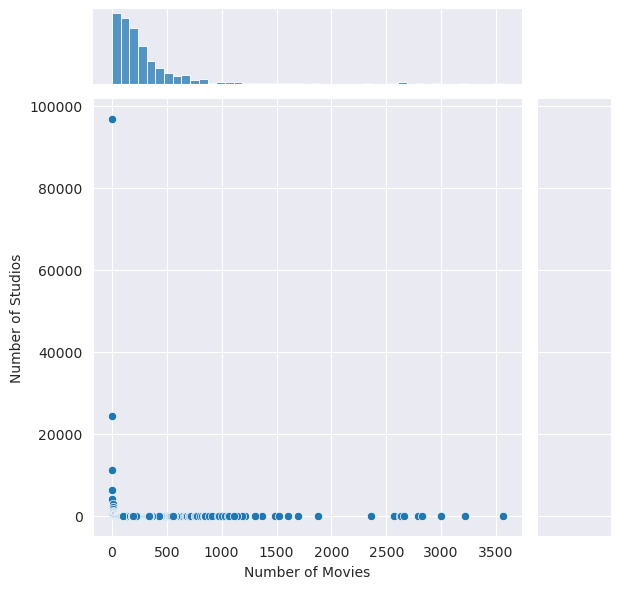

In [62]:
sns.jointplot(data=df_distribution_studios_movies, x='number_of_movies', y='number_of_studios')
# Titoli e etichette
plt.xlabel('Number of Movies')
plt.ylabel('Number of Studios')

# Mostra il grafico
plt.show()

In [63]:
fig = px.scatter(df_distribution_studios_movies, x="number_of_movies", y="number_of_studios", marginal_x="histogram")
fig.show()

- We can use a heatmap to show the distribution of the number of movies per studio

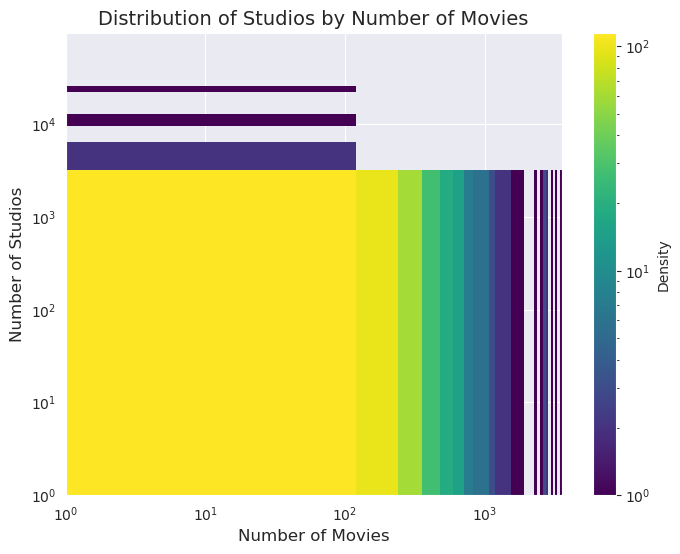

In [84]:
sns.set_style("darkgrid")

plt.figure(figsize=(8, 6))
plt.hist2d(df_distribution_studios_movies['number_of_movies'], df_distribution_studios_movies['number_of_studios'],
           bins=(30, 30), cmap="viridis", norm=plt.matplotlib.colors.LogNorm())

plt.colorbar(label="Density")

plt.title("Distribution of Studios by Number of Movies", fontsize=14)
plt.xlabel("Number of Movies", fontsize=12)
plt.ylabel("Number of Studios", fontsize=12)

plt.xscale("log")
plt.yscale("log")

plt.show()


- Now let's try to use a violin plot to show the distribution of the number of movies per studio and the number of studios per movie

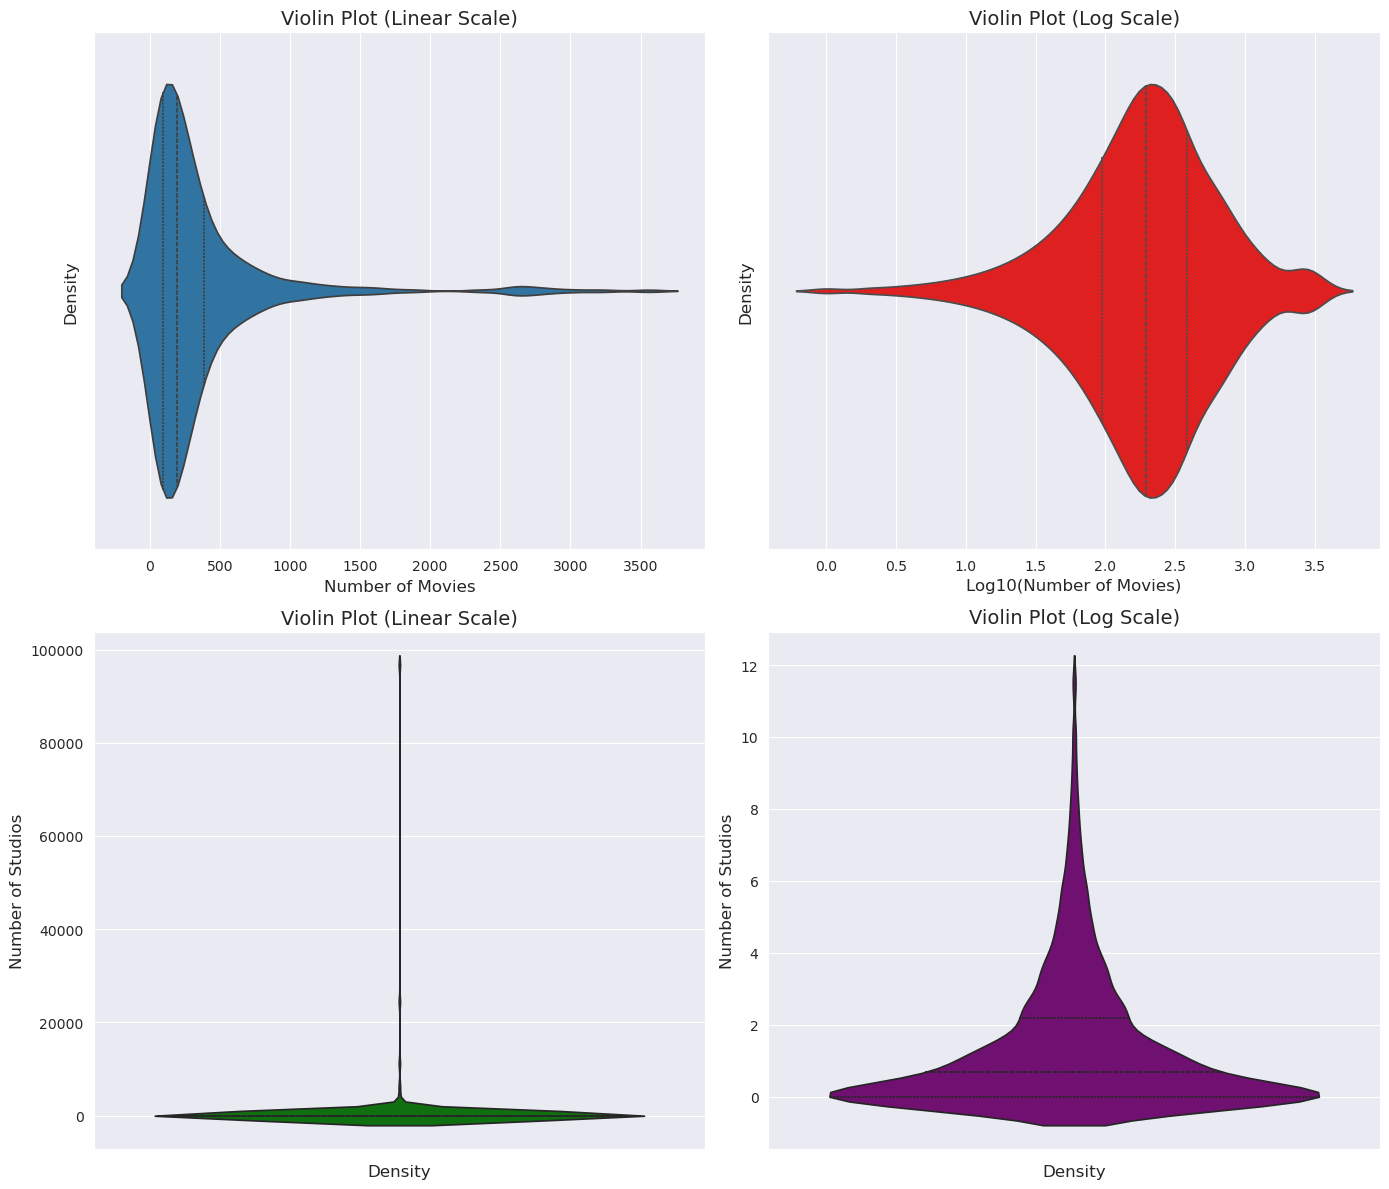

In [115]:
sns.set_style("darkgrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

sns.violinplot(ax=axes[0, 0], data=df_distribution_studios_movies, x="number_of_movies", inner="quartile",
               bw_method=0.2)
axes[0, 0].set_title("Violin Plot (Linear Scale)", fontsize=14)
axes[0, 0].set_xlabel("Number of Movies", fontsize=12)
axes[0, 0].set_ylabel("Density", fontsize=12)

sns.violinplot(ax=axes[0, 1], data=df_distribution_studios_movies,
               x=np.log10(df_distribution_studios_movies["number_of_movies"]), inner="quartile", bw_method=0.2,
               color="r")
axes[0, 1].set_title("Violin Plot (Log Scale)", fontsize=14)
axes[0, 1].set_xlabel("Log10(Number of Movies)", fontsize=12)
axes[0, 1].set_ylabel("Density", fontsize=12)

sns.violinplot(ax=axes[1, 0], data=df_distribution_studios_movies, y="number_of_studios", inner="quartile",
               bw_method=0.2, color="g")
axes[1, 0].set_title("Violin Plot (Linear Scale)", fontsize=14)
axes[1, 0].set_ylabel("Number of Studios", fontsize=12)
axes[1, 0].set_xlabel("Density", fontsize=12)

sns.violinplot(ax=axes[1, 1], data=df_distribution_studios_movies,
               y=np.log(df_distribution_studios_movies["number_of_studios"]), color='purple', inner="quartile",
               bw_method=0.2)
axes[1, 1].set_title("Violin Plot (Log Scale)", fontsize=14)
axes[1, 1].set_ylabel("Number of Studios", fontsize=12)
axes[1, 1].set_xlabel("Density", fontsize=12)

plt.tight_layout()
plt.show()
